# asignación de deliberación: Comparación con métodos publicados

**Nivel:** 3 **Requisitos previos:** Asignación de deliberación nivel 1 **Tiempo de lectura:** 25 minutos

**Pregunta:** ¿La referencia XGBoost medida supera el resultado de esta muestra de delegación a nivel de caso?

## Objetivos

Esta lección investiga la pregunta: ¿La referencia XGBoost medida supera el resultado de esta muestra de delegación a nivel de caso?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2 ```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/semantic-routing-study/analysis; - `data/derived/episodes/M11-C13-nominal-40000; - `data/derived/episodes/M12-C13-nominal-40000; - `data/derived/episodes/M09-C13-nominal-40000; - `data/derived/episodes/M10-C13-nominal-40000; json`

## Método

La investigación de valor de cómputo y aprendizaje con aplazamiento formaliza si otra computación justifica su costo. Las cantidades pertinentes incluyen utilidad incremental esperada, demora del planificador, respuesta inválida y llegada antes de que cambie el estado. Las puertas ajustadas de Neuraxis nunca delegaron con el umbral seleccionado y este resultado negativo se conserva. M04 proporciona una comparación aprendida ejecutada en la misma tarea C13; no es un planificador. Una llamada Ollama configurada sería otra medición y no se simula a partir de trazas congeladas. Un ensayo justo empareja ejecuciones rápidas y delegadas sobre la misma observación, herramientas y contrato, y registra calidad de decisión y coste temporal por separado. Los ejemplos positivos deben incluir situaciones donde deliberar cambia una decisión relevante; sin ellos, una puerta que nunca delega puede parecer exitosa sin aprender asignación. Un modelo de lenguaje es un componente externo estocástico: registra identidad, prompt, parámetros de decodificación, límites de tiempo y manejo de salidas inválidas. Una extensión útil incorpora observaciones ambiguas con valor positivo de delegación y controles negativos donde la política rápida ya es suficiente.

### asignación de deliberación · nivel 3 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M11', 'M12', 'M04']
sample_case, seed = 'C13', 40000
evidence = load_lesson_evidence(
    ROOT, topic='04-deliberation-allocation', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 3 | case variants: 18


### Comparar métodos entre variantes:

### asignación de deliberación · nivel 3 | Ejecuta las políticas publicadas y compara la corrida

### asignación de deliberación · nivel 3 | Compara la secuencia completa y no solo la primera acción

### asignación de deliberación · nivel 3 | Recalcula resultados por variante desde todas las trazas del caso

In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "éxitos=",
        sum(values),
        "episodios=",
        len(values),
        "tasa=",
        round(sum(values) / len(values), 3),
    )


M04 boundary éxitos= 10 episodios= 10 tasa= 1.0
M04 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M04 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M04 nominal éxitos= 10 episodios= 10 tasa= 1.0
M04 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M04 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M11 boundary éxitos= 10 episodios= 10 tasa= 1.0
M11 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M11 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M11 nominal éxitos= 10 episodios= 10 tasa= 1.0
M11 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M11 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M12 boundary éxitos= 10 episodios= 10 tasa= 1.0
M12 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M12 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M12 nominal éxitos= 10 episodios= 10 tasa= 1.0
M12 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M12 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0


### asignación de deliberación · nivel 3 | Visualiza el estrés por variante sin mezclar familias

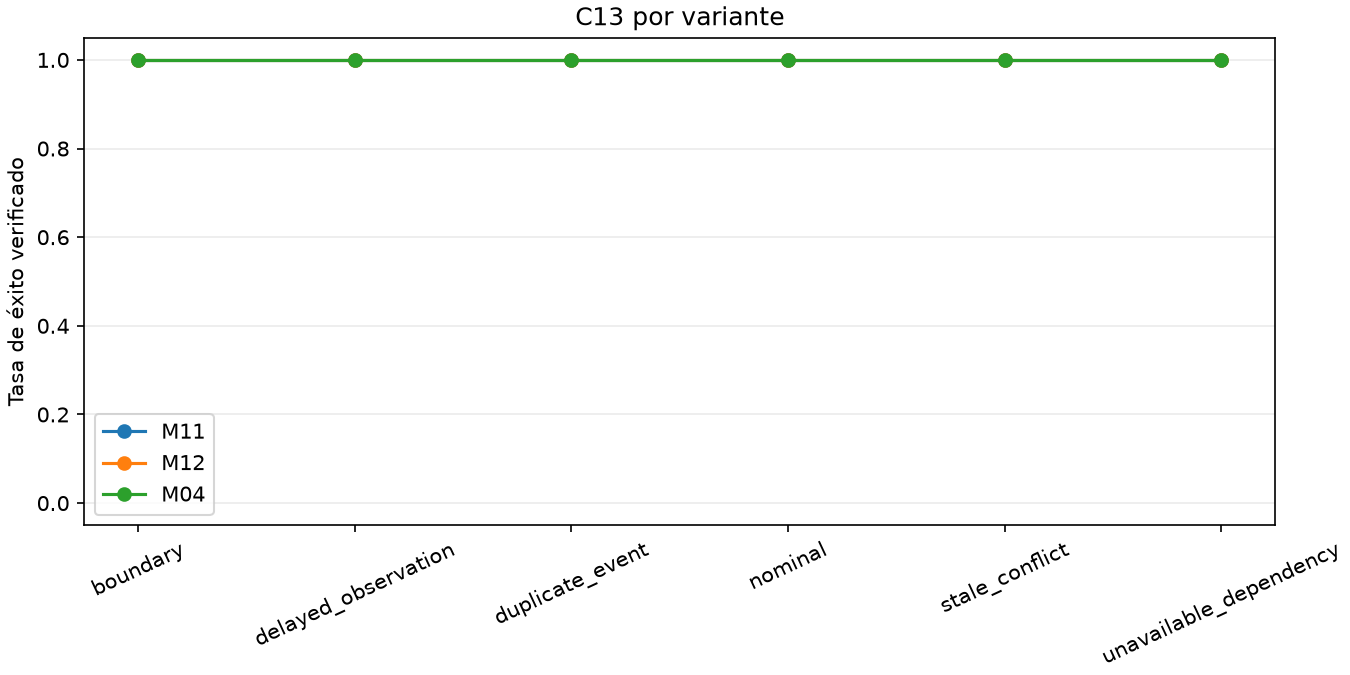

In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


revisa el resultado medido. Para el gráfico 1, el denominador contiene episodios C13 verificados contra hashes del manifiesto y conserva los fallos. El gráfico 1 describe la familia C13 de nivel 3, no incidentes reales ni rendimiento en software inédito. Interpreta el gráfico 1 de C13 con su traza y poscondición antes de llamarlo una mejora útil del control.

In [5]:
# Este experimento offline no se combina con el benchmark central.
routing = json.loads((ROOT / "data/derived/semantic-routing-study/analysis.json").read_text(encoding="utf-8"))
print(
    "umbral=",
    routing["selected_threshold"],
    "| positivos de ajuste=",
    routing["fit_positives"],
    "| positivos de calibración=",
    routing["calibration_positives"],
)
for arm, result in routing["test"].items():
    print(arm, result)


umbral= 0.44629505030857797 | positivos de ajuste= 19 | positivos de calibración= 8
always_fast_M04 {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
always_planner_M09 {'episodes': 32, 'invalid_policy_outputs': 8, 'mean_wall_ms': 20052.693393749905, 'planner_episodes': 32, 'verified_successes': 10}
hash_half {'episodes': 32, 'invalid_policy_outputs': 4, 'mean_wall_ms': 11568.068874998971, 'planner_episodes': 19, 'verified_successes': 7}
learned_gate {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
post_hoc_oracle_upper_bound {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 4085.057468750165, 'planner_episodes': 10, 'verified_successes': 10}


### asignación de deliberación · L3 | Construir la primera política ejecutable

Dentro de esta comparación de asignación de deliberación (C13), construye M11 para asignación de deliberación con la fábrica pública y conserva su contrato de observación antes de muestrear C13.

In [6]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = 'M11'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M11


### asignación de deliberación · L3 | Ejecutar el método principal en el caso indicado

En la comparación emparejada de asignación de deliberación para C13, de asignación de deliberación, el evaluador ejecuta M11 en C13 y deriva el éxito de la poscondición independiente, no de una traza reproducida.

In [7]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### asignación de deliberación · L3 | Construir una política de comparación independiente

En la comparación emparejada de asignación de deliberación para C13, crea M12 como objeto nuevo para impedir que el estado recurrente de M11 contamine la comparación.

In [8]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = 'M12'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M12


### asignación de deliberación · L3 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M12 en el mismo C13, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [9]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### asignación de deliberación · L3 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de asignación de deliberación, y las afirmaciones entre familias aún requieren el benchmark completo

In [10]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### asignación de deliberación · L3 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de asignación de deliberación recién ejecutados en C13, no se copia de un artefacto congelado

## Comparación
La investigación de valor de cómputo y aprendizaje con aplazamiento formaliza si otra computación justifica su costo. No es un planificador.

### asignación de deliberación · L3 | Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para asignación de deliberación ejecuta M04 en C13 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.

In [11]:
# Ejecuta la política XGBoost medida con la misma especificación del caso.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Ejecuciones del método de referencia:", 1)
print("Éxito de tarea de XGBoost:", state_art_result["metrics"]["task_success"])


Ejecuciones del método de referencia: 1
Éxito de tarea de XGBoost: 1


### asignación de deliberación · L3 | Tiempo registrado del controlador

la figura de tiempos de asignación de deliberación usa registros congelados y verificados por hash para M11 y M04 en C13, no los tiempos dependientes de la máquina de episodios nuevos. Esta vista de nivel 3 para asignación de deliberación describe el entorno registrado bajo su caso, variante y semilla declarados.

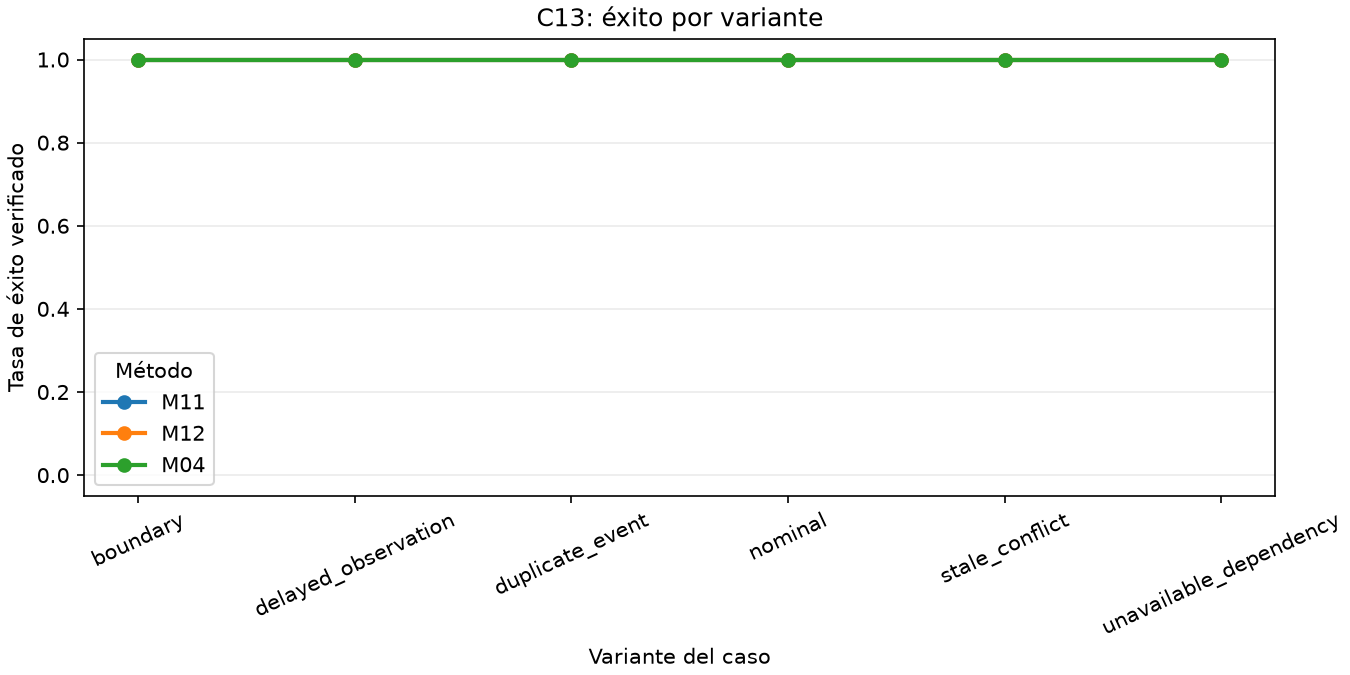

In [12]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para asignación de deliberación, estas barras muestran resultados nuevos de poscondición de M11 y M12 en C13, Éxito vale 1 y falla 0. Lee el caso y la semilla antes de compararlas. En la comparación emparejada de asignación de deliberación para C13, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

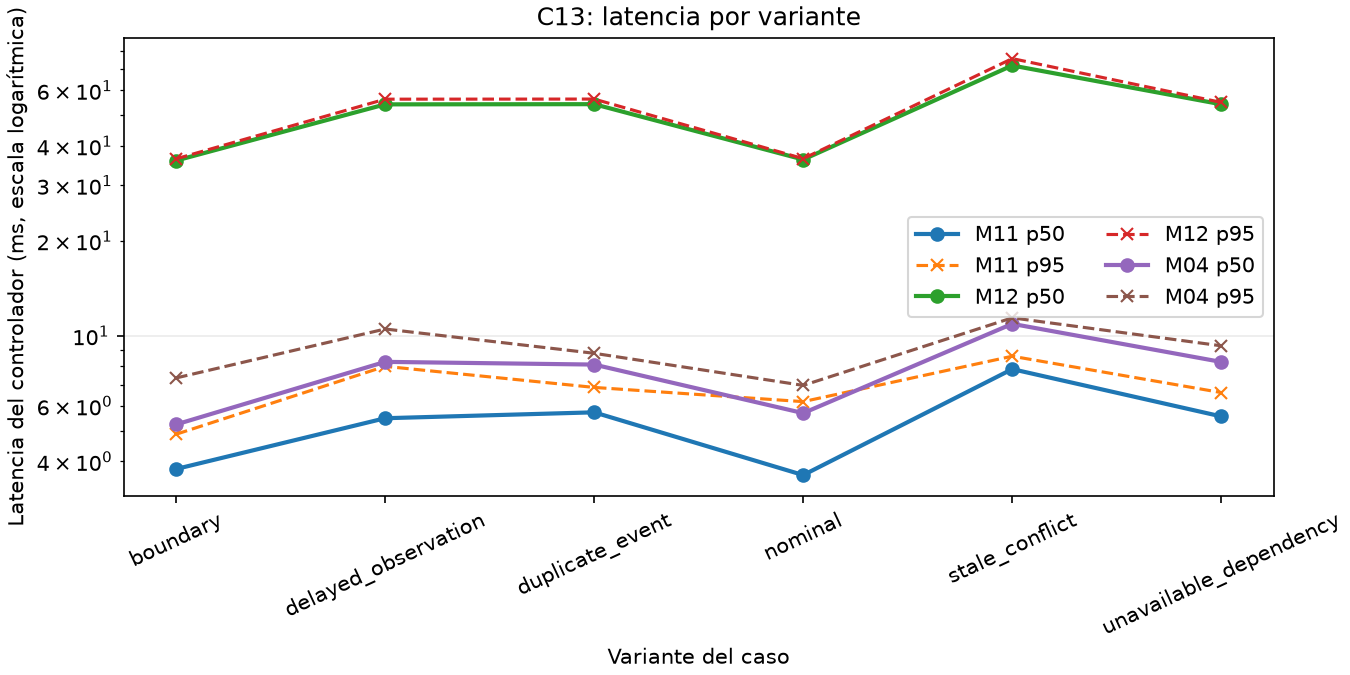

In [13]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Latencia del controlador (ms, escala logarítmica)")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": latencia por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para asignación de deliberación lee registros canónicos de M11/M04 en C13, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos. revisa el resultado medido.

El gráfico 3, nivel 3, resume latencia por familia junto con la finalización de tareas para C13.

## Resultados

**Respuesta:** La comparación de nivel 3 para asignación de deliberación contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C13; esas 3 corridas emparejadas no establecen superioridad poblacional para asignación de deliberación.

Dentro de esta comparación de asignación de deliberación (C13), el ajuste de la puerta usó 228 estados con siete etiquetas positivas y seleccionó el umbral 1,01, por lo que nunca delegó a través de esa puerta; El otro disparador de M12 es independiente. Dentro de esta comparación de asignación de deliberación (C13), informa llamadas al planificador, latencia y éxito verificado; Dentro de esta comparación de asignación de deliberación (C13), configurar un LLM no demuestra que deliberar sea útil;

En la comparación emparejada de asignación de deliberación para C13, este paso de autoría no compromete salidas generadas;

## Resumen

Las decisiones y resultados de la compuerta determinan si la asignación aportó valor.




## Referencias
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [DPT](https://aclanthology; org/2025.acl-long.206/) - [VOC](https://arxiv.org/abs/1711.06892) - [DEFER](https://proceedings.mlr.press/v119/mozannar20b.html) - DPT-Agent. Control con codigo y FSM junto al razonamiento asincrono de modelos de lenguaje. https://aclanthology.org/2025.acl-long.206/